# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170084          # <-- your full roll number
NAME = "Lalramdina Zadeng"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170084   Name: Lalramdina Zadeng   Fingerprint: 41C58EBE   Tickets: 16

Ticket_ID                                                                            Ticket_Text
      T01                           The password stopped responding. I have tried several times!
      T02                                        The Python keeps disconnecting. This is urgent.
      T03                                            The VPN was working yesterday. Please help.
      T04                                            The state-of-the-art lab (Lab-3) is closed.
      T05                               The projector failed to open. Is there another solution?
      T06               Matlab is running slowly when I use mobile hotspot. It worked yesterday.
      T07                                                  The Wi-Fi works, but the VPN doesn't.
      T08                                             The laptop failed to open. This is urgent.
      T09    I am unable to use the se

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [10]:
# Process every ticket using the official pipeline
processed = {
    row["Ticket_ID"]: process_ticket(row["Ticket_Text"])
    for _, row in df.iterrows()
}

# Create one row per ticket
rows = []

for ticket_id, r in processed.items():
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation Tokens": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique Tokens": len(set(r["tokens"])),
        "Final Tokens": len(r["final"])
    })

q1_table = pd.DataFrame(rows)

# Add total row
q1_total = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation Tokens": q1_table["Punctuation Tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique Tokens": q1_table["Unique Tokens"].sum(),
    "Final Tokens": q1_table["Final Tokens"].sum()
}])

q1_table = pd.concat([q1_table, q1_total], ignore_index=True)

print("Q1(a) Preprocessing Summary")
display(q1_table)


# ------------------------------------------------------------
# Detailed output for selected ticket T04
# ------------------------------------------------------------

selected_id = "T04"
selected = processed[selected_id]

print(f"\nQ1(b) Detailed preprocessing for {selected_id}")

print("\nTicket:")
print(df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].iloc[0])

print("\nTokens:")
print(selected["tokens"])

print("\nPunctuation tokens:")
print(selected["punct"])

print("\nStopwords:")
print(selected["stops"])

print("\nFinal tokens:")
print(selected["final"])

Q1(a) Preprocessing Summary


,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,3,11,6
1,T02,2,9,2,3,8,4
2,T03,2,9,2,2,8,5
3,T04,1,9,3,2,9,4
4,T05,2,11,2,4,11,5
5,T06,2,14,2,4,13,8
6,T07,1,10,2,4,9,4
7,T08,2,10,2,4,9,4
8,T09,2,20,2,9,16,9
9,T10,2,16,2,5,16,9



Q1(b) Detailed preprocessing for T04

Ticket:
The state-of-the-art lab (Lab-3) is closed.

Tokens:
['the', 'state-of-the-art', 'lab', '(', 'lab-3', ')', 'is', 'closed', '.']

Punctuation tokens:
['(', ')', '.']

Stopwords:
['the', 'is']

Final tokens:
['state-of-the-art', 'lab', 'lab-3', 'closed']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real standalone words include n't, 's, and ca. They come from NLTK's word_tokenize(), which splits contractions into separate tokens. For example, “doesn't” → does + n't, “it's” → it + 's, and “can't” → ca + n't. These tokens remain in the final list because they are not punctuation tokens and are not removed as stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [11]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

import re

# ------------------------------------------------------------
# REGEX PATTERNS
# ------------------------------------------------------------

# 1. Words longer than 5 letters
long_words_pattern = r"\b[A-Za-z]{6,}\b"

# 2. Numbers
#    Keeps:
#    2.0.1
#    95.5
#    5.30
#    1,250
#    0175-239-3201
#    0x80070005
numbers_pattern = (
    r"\b(?:"
    r"0[xX][0-9A-Fa-f]+"
    r"|\d{1,3}(?:,\d{3})+(?:\.\d+)?"
    r"|\d+(?:\.\d+)+(?:-\d+)*"
    r"|\d+(?:-\d+)+"
    r"|\d+"
    r")\b"
)

# 3. Capitalized words
capitalized_pattern = r"\b[A-Z][A-Za-z]*\b"

# 4. Words beginning with a vowel
vowel_words_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"


# ------------------------------------------------------------
# REPLACEMENT PATTERNS
# ------------------------------------------------------------

# Email addresses
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

# URLs
url_pattern = r"(?:https?://|www\.)[^\s]+"

# Phone numbers
phone_pattern = (
    r"(?<!\w)"
    r"(?:\+\d{1,3}[-.\s]?)?"
    r"(?:\d{3,5}[-.\s]\d{3,5}[-.\s]\d{4}|\d{10})"
    r"(?!\w)"
)


# ============================================================
# PART A — FINDALL ON TEST_LINES
# ============================================================

print("=" * 70)
print("REGEX EXTRACTION ON TEST_LINES")
print("=" * 70)

for i, line in enumerate(TEST_LINES, 1):

    print(f"\nTEST LINE {i}")
    print("-" * 70)
    print(line)

    print("\nWords longer than 5 letters:")
    print(re.findall(long_words_pattern, line))

    print("\nNumbers:")
    print(re.findall(numbers_pattern, line))

    print("\nCapitalized words:")
    print(re.findall(capitalized_pattern, line))

    print("\nWords beginning with a vowel:")
    print(re.findall(vowel_words_pattern, line))


# ============================================================
# PART B — FINDALL ON ALL RAW TICKETS
# ============================================================

raw_tickets = "\n".join(df["Ticket_Text"])

print("\n\n" + "=" * 70)
print("REGEX EXTRACTION ON GENERATED TICKETS")
print("=" * 70)

print("\nWords longer than 5 letters:")
print(re.findall(long_words_pattern, raw_tickets))

print("\nNumbers:")
print(re.findall(numbers_pattern, raw_tickets))

print("\nCapitalized words:")
print(re.findall(capitalized_pattern, raw_tickets))

print("\nWords beginning with a vowel:")
print(re.findall(vowel_words_pattern, raw_tickets))


# ============================================================
# PART C — re.sub() ON TEST_LINES
# ============================================================

print("\n\n" + "=" * 70)
print("REGEX REPLACEMENT ON TEST_LINES")
print("=" * 70)

for i, line in enumerate(TEST_LINES, 1):

    replaced = line

    # Replace email addresses
    replaced = re.sub(email_pattern, "<EMAIL>", replaced)

    # Replace URLs
    replaced = re.sub(url_pattern, "<URL>", replaced)

    # Replace phone numbers
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    print(f"\nTEST LINE {i}")
    print("Original :", line)
    print("Replaced :", replaced)


# ============================================================
# PART D — re.sub() ON ALL GENERATED TICKETS
# ============================================================

print("\n\n" + "=" * 70)
print("REGEX REPLACEMENT ON GENERATED TICKETS")
print("=" * 70)

for _, row in df.iterrows():

    replaced = row["Ticket_Text"]

    replaced = re.sub(email_pattern, "<EMAIL>", replaced)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    # Only print tickets where something was replaced
    if replaced != row["Ticket_Text"]:
        print(f"\n{row['Ticket_ID']}")
        print("Original :", row["Ticket_Text"])
        print("Replaced :", replaced)

REGEX EXTRACTION ON TEST_LINES

TEST LINE 1
----------------------------------------------------------------------
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

Words longer than 5 letters:
['helpdesk', 'thapar', 'thapar', 'thapar']

Numbers:
[]

Capitalized words:
['Mail']

Words beginning with a vowel:
['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

TEST LINE 2
----------------------------------------------------------------------
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Words longer than 5 letters:
['Version']

Numbers:
['91', '98765', '43210', '91-98765-43210', '0175-239-3201', '2.0.1', '95.5', '1,250']

Capitalized words:
['Call', 'Version', 'Rs']

Words beginning with a vowel:
['or', 'is']

TEST LINE 3
----------------------------------------------------------------------
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
# Your code


from nltk.tokenize import RegexpTokenizer, word_tokenize

# One RegexpTokenizer pattern
custom_pattern = r"""
    https?://[^\s]+                                      # URLs
    |www\.[^\s]+
    |[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}      # emails
    |\+?\d{1,3}(?:[-.\s]\d{3,5}){2,}                    # phone numbers
    |\d+(?:\.\d+)+                                      # decimals / versions
    |[A-Za-z]+(?:-[A-Za-z]+)+                           # hyphenated words
    |[A-Za-z]+(?:'[A-Za-z]+)+                           # contractions
    |[A-Za-z]+                                          # ordinary words
    |\d+(?:,\d{3})*                                     # numbers
    |[^\w\s]                                            # punctuation
"""

tokenizer = RegexpTokenizer(custom_pattern, flags=re.VERBOSE)


def my_tokenize(text):
    return tokenizer.tokenize(text)


# ============================================================
# 1. RUN ON TEST_LINES
# ============================================================

print("=" * 70)
print("CUSTOM TOKENIZER ON TEST_LINES")
print("=" * 70)

for i, line in enumerate(TEST_LINES, 1):

    custom = my_tokenize(line)
    nltk_tokens = word_tokenize(line)

    print(f"\nTEST LINE {i}")
    print("Original:")
    print(line)

    print("\nmy_tokenize():")
    print(custom)

    print("\nword_tokenize():")
    print(nltk_tokens)


# ============================================================
# 2. RUN ON ALL GENERATED TICKETS
# ============================================================

print("\n\n" + "=" * 70)
print("CUSTOM TOKENIZER VS word_tokenize() ON TICKETS")
print("=" * 70)

for _, row in df.iterrows():

    custom = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])

    print(f"\n{row['Ticket_ID']}")
    print(row["Ticket_Text"])

    print("my_tokenize():")
    print(custom)

    print("word_tokenize():")
    print(nltk_tokens)


# ============================================================
# 3. SHOW ONLY TICKETS WHERE THE OUTPUTS DIFFER
# ============================================================

print("\n\n" + "=" * 70)
print("TICKETS WITH DIFFERENT TOKENIZATION")
print("=" * 70)

for _, row in df.iterrows():

    custom = my_tokenize(row["Ticket_Text"])
    nltk_tokens = word_tokenize(row["Ticket_Text"])

    if custom != nltk_tokens:
        print(f"\n{row['Ticket_ID']}")
        print("Text :", row["Ticket_Text"])
        print("Custom:", custom)
        print("NLTK  :", nltk_tokens)

CUSTOM TOKENIZER ON TEST_LINES

TEST LINE 1
Original:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

my_tokenize():
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize():
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST LINE 2
Original:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

my_tokenize():
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

word_tokenize():
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*12 out of 16 tickets are tokenized differently by my_tokenize() and word_tokenize()

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
import nltk

# ------------------------------------------------------------
# 1. Collect UNIQUE final tokens from the official pipeline
# ------------------------------------------------------------

unique_final_tokens = sorted({
    token
    for ticket in processed.values()
    for token in ticket["final"]
})

print("Number of unique final tokens:", len(unique_final_tokens))
print("\nUnique final tokens:")
print(unique_final_tokens)


# ------------------------------------------------------------
# 2. Initialize stemmers / lemmatizer
# ------------------------------------------------------------

porter = PorterStemmer()
lancaster = LancasterStemmer()

# RegexpStemmer suffix chosen after examining our dataset.
# "ing" occurs in words such as:
# working, running, opening, responding, syncing,
# uploading, restarting, etc.
regexp_stemmer = RegexpStemmer(r"ing$")

lemmatizer = WordNetLemmatizer()


# ------------------------------------------------------------
# 3. Convert NLTK POS tags to WordNet POS tags
# ------------------------------------------------------------

def get_wordnet_pos(tag):
    """
    Convert Penn Treebank POS tags returned by nltk.pos_tag()
    into WordNet POS tags.
    """
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN


# POS tagging must be done on the unique final tokens
pos_tags = nltk.pos_tag(unique_final_tokens)


# ------------------------------------------------------------
# 4. Generate all four outputs
# ------------------------------------------------------------

results = []

for word, tag in pos_tags:

    wn_pos = get_wordnet_pos(tag)

    results.append({
        "Word": word,
        "POS": tag,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "WordNet": lemmatizer.lemmatize(word, pos=wn_pos)
    })


stem_table = pd.DataFrame(results)


# ------------------------------------------------------------
# 5. Show ONLY words where outputs differ
# ------------------------------------------------------------

output_columns = ["Porter", "Lancaster", "Regexp", "WordNet"]

different = stem_table[
    stem_table[output_columns].nunique(axis=1) > 1
].reset_index(drop=True)

print("\n" + "=" * 80)
print("WORDS WHERE STEMMING / LEMMATIZATION OUTPUTS DIFFER")
print("=" * 80)

display(different)

Number of unique final tokens: 58

Unique final tokens:
['1023-03-021', '11', '5.30', 'access', 'another', 'asking', 'campus', 'changed', 'closed', 'connect', 'connected', 'could', 'disconnecting', 'e-mail', 'failed', 'help', 'hotspot', 'keeps', 'know', 'lab', 'lab-3', 'laptop', 'login', 'matlab', 'mobile', "n't", 'need', 'open', 'p.m.', 'password', 'please', 'projector', 'python', 'resetting', 'responding', 'roll', 'running', 'server', 'several', 'slowly', 'solution', 'state-of-the-art', 'stopped', 'syncing', 'times', 'today', 'tried', 'unable', 'urgent', 'use', 'vpn', 'wi-fi', 'wifi', 'windows', 'worked', 'working', 'works', 'yesterday']

WORDS WHERE STEMMING / LEMMATIZATION OUTPUTS DIFFER


,Word,POS,Porter,Lancaster,Regexp,WordNet
0,another,DT,anoth,anoth,another,another
1,campus,NN,campu,camp,campus,campus
2,changed,VBD,chang,chang,changed,change
3,closed,JJ,close,clos,closed,closed
4,connected,VBN,connect,connect,connected,connect
5,failed,JJ,fail,fail,failed,failed
6,keeps,NNS,keep,keep,keeps,keep
7,mobile,VBP,mobil,mobl,mobile,mobile
8,need,VB,need,nee,need,need
9,open,JJ,open,op,open,open


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*
Over-stemming: running → run — the stemmer removes too much of the original form, producing a stem that may lose useful morphological information.


Under-stemming: working → work — if compared with another related form that should reduce to the same root but does not, the stemmer has failed to fully reduce the word.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Total Tokens,Unique Tokens,TTR
S1,195.0,88.0,0.451282
S2,163.0,82.0,0.503067
S3,93.0,58.0,0.623656
S4,93.0,55.0,0.591398



TOP 10 WORDS — S1
.                    25
the                  13
i                    11
is                   9
to                   5
when                 4
use                  4
n't                  4
this                 3
urgent               3

TOP 10 WORDS — S3
use                  4
n't                  4
urgent               3
lab                  3
mobile               3
hotspot              3
password             2
stopped              2
tried                2
several              2


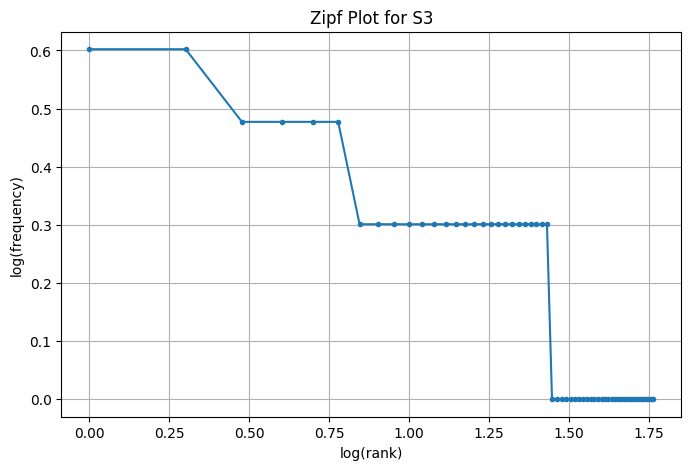


TOP 5 BIGRAMS — S1
('.', 'i') : 7
('.', 'the') : 5
('.', 'this') : 3
('this', 'is') : 3
('is', 'urgent') : 3

TOP 5 BIGRAMS — S3
('use', 'mobile') : 3
('mobile', 'hotspot') : 3
('tried', 'several') : 2
('several', 'times') : 2
('please', 'help') : 2


In [14]:
# Your code
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
import math
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Construct S1, S2, S3 and S4
# ------------------------------------------------------------

# S1 = all tokens
S1 = [
    token
    for ticket in processed.values()
    for token in ticket["tokens"]
]

# S2 = tokens without punctuation
S2 = [
    token
    for ticket in processed.values()
    for token in ticket["tokens"]
    if not is_punct(token)
]

# S3 = final tokens
S3 = [
    token
    for ticket in processed.values()
    for token in ticket["final"]
]

# S4 = S3 after Porter stemming
porter = PorterStemmer()

S4 = [
    porter.stem(token)
    for token in S3
]


# ------------------------------------------------------------
# 2. Corpus statistics
# ------------------------------------------------------------

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0

    return {
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": ttr
    }


stats = pd.DataFrame({
    "S1": corpus_stats(S1),
    "S2": corpus_stats(S2),
    "S3": corpus_stats(S3),
    "S4": corpus_stats(S4)
}).T

print("=" * 70)
print("CORPUS STATISTICS")
print("=" * 70)

display(stats)


# ------------------------------------------------------------
# 3. Top 10 words of S1 and S3
# ------------------------------------------------------------

s1_freq = Counter(S1)
s3_freq = Counter(S3)

print("\n" + "=" * 70)
print("TOP 10 WORDS — S1")
print("=" * 70)

for word, freq in s1_freq.most_common(10):
    print(f"{word:20s} {freq}")


print("\n" + "=" * 70)
print("TOP 10 WORDS — S3")
print("=" * 70)

for word, freq in s3_freq.most_common(10):
    print(f"{word:20s} {freq}")


# ------------------------------------------------------------
# 4. Zipf plot: log(rank) vs log(frequency) for S3
# ------------------------------------------------------------

ranked_s3 = s3_freq.most_common()

ranks = list(range(1, len(ranked_s3) + 1))
frequencies = [freq for word, freq in ranked_s3]

log_ranks = [math.log10(r) for r in ranks]
log_frequencies = [math.log10(f) for f in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o", markersize=3)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf Plot for S3")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 5. Top 5 bigrams of S1
# ------------------------------------------------------------

s1_bigrams = Counter(bigrams(S1))

print("\n" + "=" * 70)
print("TOP 5 BIGRAMS — S1")
print("=" * 70)

for pair, freq in s1_bigrams.most_common(5):
    print(f"{pair} : {freq}")


# ------------------------------------------------------------
# 6. Top 5 bigrams of S3
# ------------------------------------------------------------

s3_bigrams = Counter(bigrams(S3))

print("\n" + "=" * 70)
print("TOP 5 BIGRAMS — S3")
print("=" * 70)

for pair, freq in s3_bigrams.most_common(5):
    print(f"{pair} : {freq}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, reducing the total number of tokens, while Porter stemming also combines different word forms into the same stem, reducing the number of unique tokens. Therefore, the ratio of unique tokens to total tokens changes, and in my dataset the TTR generally decreases after stemming.